In [1]:
import pandas as pd
import numpy as np
import os
import joblib
import json
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
sales = pd.read_csv(
    "../data/processed/feature_engineered_sales.csv"
)

sales["InvoiceDate"] = pd.to_datetime(
    sales["InvoiceDate"],
    errors="coerce"
)

print("Shape:", sales.shape)

sales.head()

Shape: (779425, 48)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,Revenue,Year,Month,MonthName,Quarter,Day,DayName,DayOfWeek,WeekOfYear,Date,Hour,IsWeekend,IsWeekday,YearMonth,WeekStart,MonthStart,InvoiceQuantity,InvoiceRevenue,InvoiceItems,InvoiceCustomers,CustomerRevenue,CustomerQuantity,CustomerOrders,CustomerProducts,CustomerCountries,FirstPurchase,LastPurchase,AverageOrderValue,CustomerLifetimeDays,OrdersPerLifetimeDay,ProductQuantity,ProductRevenue,ProductOrders,ProductCustomers,ProductFirstSale,ProductLastSale,ProductAveragePrice,CustomerRevenueShare,ProductRevenueShare
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4,2009,12,December,4,1,Tuesday,1,49,2009-12-01,7,0,1,2009-12,2009-11-30,2009-12-01,166,505.3,8,1,2433.28,944,8,50,1,2009-12-01 07:45:00,2011-07-05 12:11:00,304.16,581,0.013769,2525,18618.75,432,309,2009-12-01 07:45:00,2011-12-07 14:34:00,7.750915,0.00014,0.001072
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,December,4,1,Tuesday,1,49,2009-12-01,7,0,1,2009-12,2009-11-30,2009-12-01,166,505.3,8,1,2433.28,944,8,50,1,2009-12-01 07:45:00,2011-07-05 12:11:00,304.16,581,0.013769,2234,13198.10,229,132,2009-12-01 07:45:00,2011-01-11 13:54:00,6.426087,0.00014,0.000760
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,December,4,1,Tuesday,1,49,2009-12-01,7,0,1,2009-12,2009-11-30,2009-12-01,166,505.3,8,1,2433.28,944,8,50,1,2009-12-01 07:45:00,2011-07-05 12:11:00,304.16,581,0.013769,2948,17384.80,313,174,2009-12-01 07:45:00,2010-09-16 09:07:00,6.398089,0.00014,0.001001
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8,2009,12,December,4,1,Tuesday,1,49,2009-12-01,7,0,1,2009-12,2009-11-30,2009-12-01,166,505.3,8,1,2433.28,944,8,50,1,2009-12-01 07:45:00,2011-07-05 12:11:00,304.16,581,0.013769,6845,15088.77,319,101,2009-12-01 07:45:00,2011-12-08 12:07:00,2.454954,0.00014,0.000868
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0,2009,12,December,4,1,Tuesday,1,49,2009-12-01,7,0,1,2009-12,2009-11-30,2009-12-01,166,505.3,8,1,2433.28,944,8,50,1,2009-12-01 07:45:00,2011-07-05 12:11:00,304.16,581,0.013769,34935,40994.71,1893,689,2009-12-01 07:45:00,2011-12-08 15:31:00,1.239695,0.00014,0.002359


In [4]:
required_columns = [
    "Customer ID",
    "Invoice",
    "InvoiceDate",
    "Quantity",
    "Revenue"
]

missing_columns = [
    col for col in required_columns
    if col not in sales.columns
]

print("Missing required columns:", missing_columns)

Missing required columns: []


In [6]:
sales = sales[
    sales["Customer ID"].notna()
].copy()

print(
    "Rows after Customer ID validation:",
    len(sales)
)

Rows after Customer ID validation: 779425


In [7]:
# Define observation and churn periods

# Find the last transaction date.  

max_date = sales["InvoiceDate"].max()

print("Latest transaction date:", max_date)


Latest transaction date: 2011-12-09 12:50:00


In [8]:
churn_window_days = 90

churn_cutoff = (
    max_date -
    pd.Timedelta(days=churn_window_days)
)

print("Churn cutoff:", churn_cutoff)

Churn cutoff: 2011-09-10 12:50:00


In [9]:
# # Create historical customer features  
# We only use purchases before the churn cutoff to create the model features.

historical_sales = sales[
    sales["InvoiceDate"] < churn_cutoff
].copy()

print(
    "Historical observation rows:",
    len(historical_sales)
)

print(
    "Historical date range:",
    historical_sales["InvoiceDate"].min(),
    "→",
    historical_sales["InvoiceDate"].max()
)



Historical observation rows: 620572
Historical date range: 2009-12-01 07:45:00 → 2011-09-09 15:53:00


In [10]:
# Create customer features

# For each customer we calculate:

# Recency
# Frequency
# Monetary
# Number of products
# Average order value
# Lifetime
# # Average quantity

In [12]:
customer_ml = (
    historical_sales
    .groupby("Customer ID")
    .agg(
        Recency=(
            "InvoiceDate",
            lambda x: (
                churn_cutoff - x.max()
            ).days
        ),
        Frequency=(
            "Invoice",
            "nunique"
        ),
        Monetary=(
            "Revenue",
            "sum"
        ),
        TotalQuantity=(
            "Quantity",
            "sum"
        ),
        UniqueProducts=(
            "StockCode",
            "nunique"
        ),
        FirstPurchase=(
            "InvoiceDate",
            "min"
        ),
        LastPurchase=(
            "InvoiceDate",
            "max"
        )
    )
    .reset_index()
)

customer_ml.head()

,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,FirstPurchase,LastPurchase
0,12346.0,235,12,77556.46,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00
1,12347.0,39,6,3402.39,2099,107,2010-10-31 14:20:00,2011-08-02 08:48:00
2,12348.0,158,4,1709.40,2497,25,2010-09-27 14:59:00,2011-04-05 10:47:00
3,12349.0,317,3,2671.14,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00
4,12350.0,219,1,334.40,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00


In [13]:
# Calculate customer lifetime  

customer_ml["CustomerLifetimeDays"] = (
    customer_ml["LastPurchase"] -
    customer_ml["FirstPurchase"]
).dt.days

customer_ml.head()

,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,FirstPurchase,LastPurchase,CustomerLifetimeDays
0,12346.0,235,12,77556.46,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,400
1,12347.0,39,6,3402.39,2099,107,2010-10-31 14:20:00,2011-08-02 08:48:00,274
2,12348.0,158,4,1709.40,2497,25,2010-09-27 14:59:00,2011-04-05 10:47:00,189
3,12349.0,317,3,2671.14,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00,181
4,12350.0,219,1,334.40,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,0


In [14]:
## Calculate average order value  

customer_ml["AverageOrderValue"] = (
    customer_ml["Monetary"] /
    customer_ml["Frequency"]
)

customer_ml.head()


,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,FirstPurchase,LastPurchase,CustomerLifetimeDays,AverageOrderValue
0,12346.0,235,12,77556.46,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,400,6463.038333
1,12347.0,39,6,3402.39,2099,107,2010-10-31 14:20:00,2011-08-02 08:48:00,274,567.065000
2,12348.0,158,4,1709.40,2497,25,2010-09-27 14:59:00,2011-04-05 10:47:00,189,427.350000
3,12349.0,317,3,2671.14,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00,181,890.380000
4,12350.0,219,1,334.40,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,0,334.400000


In [15]:
## Calculate average quantity per order  

customer_ml["AverageQuantityPerOrder"] = (
    customer_ml["TotalQuantity"] /
    customer_ml["Frequency"]
)

customer_ml.head()

,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,FirstPurchase,LastPurchase,CustomerLifetimeDays,AverageOrderValue,AverageQuantityPerOrder
0,12346.0,235,12,77556.46,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,400,6463.038333,6190.416667
1,12347.0,39,6,3402.39,2099,107,2010-10-31 14:20:00,2011-08-02 08:48:00,274,567.065000,349.833333
2,12348.0,158,4,1709.40,2497,25,2010-09-27 14:59:00,2011-04-05 10:47:00,189,427.350000,624.250000
3,12349.0,317,3,2671.14,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00,181,890.380000,331.000000
4,12350.0,219,1,334.40,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,0,334.400000,197.000000


In [16]:
# Calculate purchase frequency  

customer_ml["OrdersPerMonth"] = (
    customer_ml["Frequency"] /
    (
        customer_ml["CustomerLifetimeDays"] /
        30
    ).replace(0, np.nan)
)

customer_ml["OrdersPerMonth"] = (
    customer_ml["OrdersPerMonth"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

customer_ml.head()

,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,FirstPurchase,LastPurchase,CustomerLifetimeDays,AverageOrderValue,AverageQuantityPerOrder,OrdersPerMonth
0,12346.0,235,12,77556.46,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,400,6463.038333,6190.416667,0.900000
1,12347.0,39,6,3402.39,2099,107,2010-10-31 14:20:00,2011-08-02 08:48:00,274,567.065000,349.833333,0.656934
2,12348.0,158,4,1709.40,2497,25,2010-09-27 14:59:00,2011-04-05 10:47:00,189,427.350000,624.250000,0.634921
3,12349.0,317,3,2671.14,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00,181,890.380000,331.000000,0.497238
4,12350.0,219,1,334.40,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,0,334.400000,197.000000,0.000000


In [18]:
# Create the churn target

# Now examine whether each historical customer purchased during the final 90-day period.  


future_sales = sales[
    sales["InvoiceDate"] >= churn_cutoff
].copy()

future_customers = set(
    future_sales["Customer ID"].unique()
)

print(
    "Customers who purchased during holdout:",
    len(future_customers)
)

Customers who purchased during holdout: 2889


In [20]:
customer_ml["Churn"] = ( 
    ~customer_ml["Customer ID"]
    .isin(future_customers)
).astype(int)

customer_ml.head()

,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,FirstPurchase,LastPurchase,CustomerLifetimeDays,AverageOrderValue,AverageQuantityPerOrder,OrdersPerMonth,Churn
0,12346.0,235,12,77556.46,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,400,6463.038333,6190.416667,0.900000,1
1,12347.0,39,6,3402.39,2099,107,2010-10-31 14:20:00,2011-08-02 08:48:00,274,567.065000,349.833333,0.656934,0
2,12348.0,158,4,1709.40,2497,25,2010-09-27 14:59:00,2011-04-05 10:47:00,189,427.350000,624.250000,0.634921,0
3,12349.0,317,3,2671.14,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00,181,890.380000,331.000000,0.497238,0
4,12350.0,219,1,334.40,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,0,334.400000,197.000000,0.000000,1


In [21]:
# Check churn distribution  

churn_counts = (
    customer_ml["Churn"]
    .value_counts()
    .sort_index()
)

print(churn_counts)

Churn
0    2292
1    2989
Name: count, dtype: int64


In [22]:
churn_percentage = (
    customer_ml["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(churn_percentage)

Churn
1    56.6
0    43.4
Name: proportion, dtype: float64


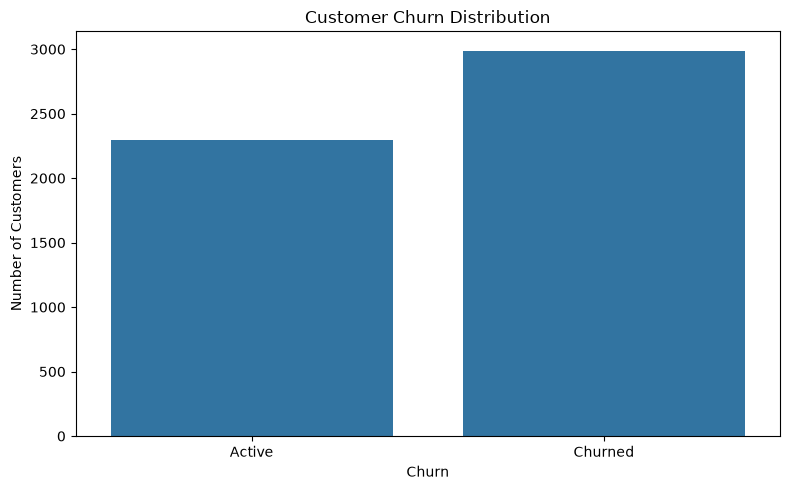

In [23]:
# Visualize churn distribution   

plt.figure(figsize=(8, 5))

sns.countplot(
    data=customer_ml,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.xticks(
    [0, 1],
    ["Active", "Churned"]
)

plt.tight_layout()
plt.show()

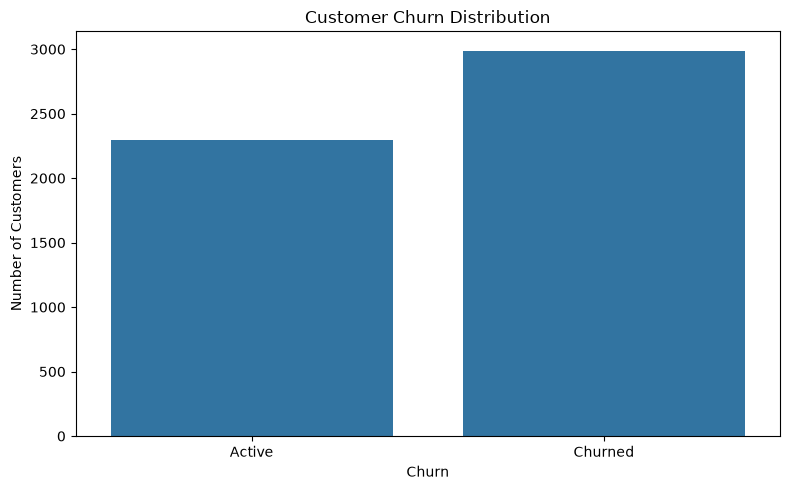

In [24]:
# Save churn distribution

figure_dir = "../reports/figures"

os.makedirs(
    figure_dir,
    exist_ok=True
)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=customer_ml,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.xticks(
    [0, 1],
    ["Active", "Churned"]
)

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
# Inspect differences between active and churned customers  

churn_profile = (
    customer_ml
    .groupby("Churn")
    .agg(
        Customers=("Customer ID", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean"),
        AvgQuantity=("TotalQuantity", "mean"),
        AvgProducts=("UniqueProducts", "mean"),
        AvgOrderValue=("AverageOrderValue", "mean")
    )
    .reset_index()
)

churn_profile

,Churn,Customers,AvgRecency,AvgFrequency,AvgMonetary,AvgQuantity,AvgProducts,AvgOrderValue
0,0,2292,120.043194,9.254799,4598.242739,2744.109948,112.021379,395.040284
1,1,2989,274.179324,3.054868,1134.621498,760.475075,45.475075,349.548652


## ML features

<!-- We should not use:

CustomerID
FirstPurchase
LastPurchase

as model features.

Use:

Recency
Frequency
Monetary
TotalQuantity
UniqueProducts
CustomerLifetimeDays
AverageOrderValue
AverageQuantityPerOrder
OrdersPerMonth -->

In [ ]:
# We should not use:

# CustomerID
# FirstPurchase
# LastPurchase

# as model features.

# Use:

# Recency
# Frequency
# Monetary
# TotalQuantity
# UniqueProducts
# CustomerLifetimeDays
# AverageOrderValue
# AverageQuantityPerOrder
# OrdersPerMonth

In [26]:
feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "UniqueProducts",
    "CustomerLifetimeDays",
    "AverageOrderValue",
    "AverageQuantityPerOrder",
    "OrdersPerMonth"
]

X = customer_ml[
    feature_columns
].copy()

y = customer_ml[
    "Churn"
].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5281, 9)
y shape: (5281,)


In [27]:
print(X.isna().sum())

Recency                    0
Frequency                  0
Monetary                   0
TotalQuantity              0
UniqueProducts             0
CustomerLifetimeDays       0
AverageOrderValue          0
AverageQuantityPerOrder    0
OrdersPerMonth             0
dtype: int64


In [28]:
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(0)

print(
    "Remaining missing values:",
    X.isna().sum().sum()
)

Remaining missing values: 0


  ## Train/test split

We need a separate model-validation set.

Because the churn target itself is constructed from the final 90-day holdout, the customer-level classification dataset can be split randomly after target creation; the target construction itself remains time-based.

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4224
Testing samples: 1057


In [30]:
# Train Logistic Regression

# Logistic Regression gives us a strong interpretable baseline.   

logistic_model = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression trained.")



Logistic Regression trained.


In [31]:
## Generate Logistic predictions

logistic_pred = logistic_model.predict(
    X_test
)

logistic_proba = logistic_model.predict_proba(
    X_test
)[:, 1]


In [32]:
## Evaluate Logistic Regression  

logistic_accuracy = accuracy_score(
    y_test,
    logistic_pred
)

logistic_precision = precision_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_recall = recall_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_auc = roc_auc_score(
    y_test,
    logistic_proba
)

print("Logistic Regression")
print("-------------------")
print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1       :", round(logistic_f1, 4))
print("ROC-AUC  :", round(logistic_auc, 4))


Logistic Regression
-------------------
Accuracy : 0.7332
Precision: 0.7926
Recall   : 0.7157
F1       : 0.7522
ROC-AUC  : 0.8001


In [33]:
# Classification report  

print(
    classification_report(
        y_test,
        logistic_pred,
        target_names=[
            "Active",
            "Churned"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Active       0.67      0.76      0.71       459
     Churned       0.79      0.72      0.75       598

    accuracy                           0.73      1057
   macro avg       0.73      0.74      0.73      1057
weighted avg       0.74      0.73      0.73      1057



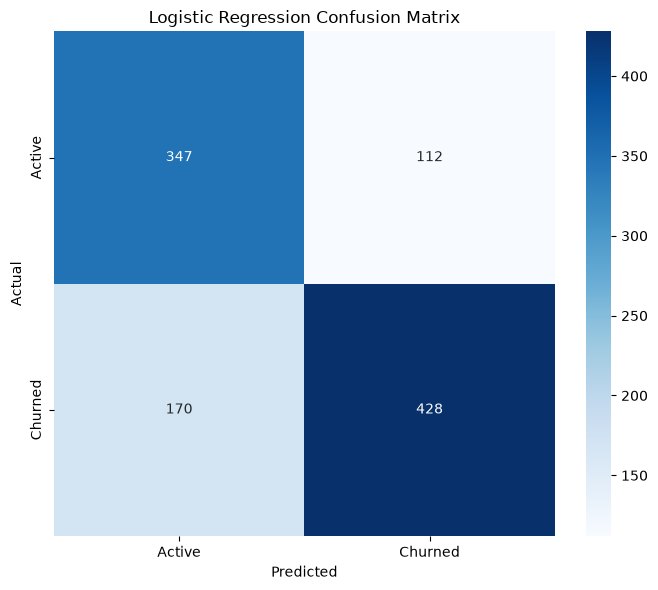

In [34]:
# Confusion matrix   

cm_logistic = confusion_matrix(
    y_test,
    logistic_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Active", "Churned"],
    yticklabels=["Active", "Churned"]
)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()


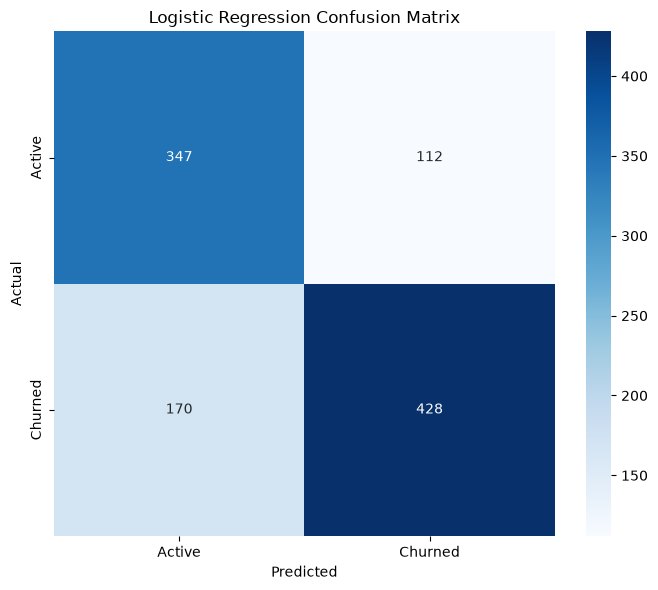

In [35]:
# Save Logistic confusion matrix  

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Active", "Churned"],
    yticklabels=["Active", "Churned"]
)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/logistic_churn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [36]:
# Train Random Forest

# Now we create a nonlinear ML model.  

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest trained.")

Random Forest trained.


In [37]:
# Generate Random Forest predictions 

rf_pred = random_forest_model.predict(
    X_test
)

rf_proba = random_forest_model.predict_proba(
    X_test
)[:, 1]

In [38]:
# Evaluate Random Forest  

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_auc = roc_auc_score(
    y_test,
    rf_proba
)

print("Random Forest")
print("-------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1       :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_auc, 4))

Random Forest
-------------
Accuracy : 0.7521
Precision: 0.7736
Recall   : 0.7943
F1       : 0.7838
ROC-AUC  : 0.8126


In [39]:
# Random Forest classification report 

print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            "Active",
            "Churned"
        ],
        zero_division=0
    )
)


              precision    recall  f1-score   support

      Active       0.72      0.70      0.71       459
     Churned       0.77      0.79      0.78       598

    accuracy                           0.75      1057
   macro avg       0.75      0.75      0.75      1057
weighted avg       0.75      0.75      0.75      1057



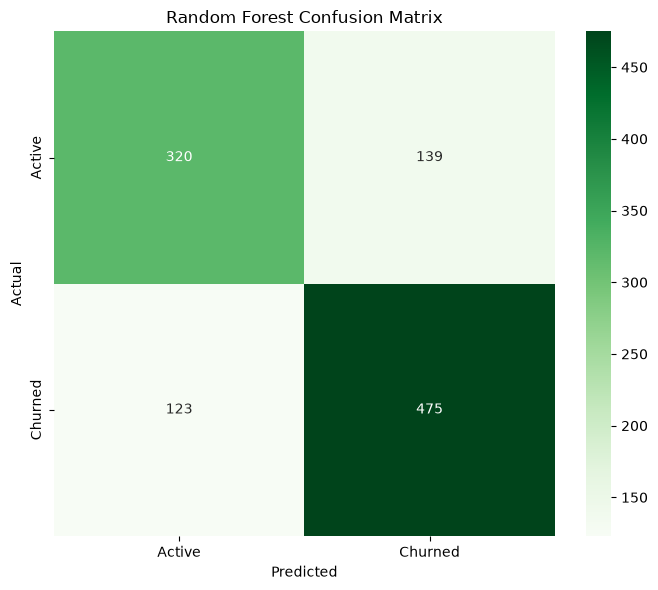

In [40]:
# Random Forest confusion matrix 

cm_rf = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Active", "Churned"],
    yticklabels=["Active", "Churned"]
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

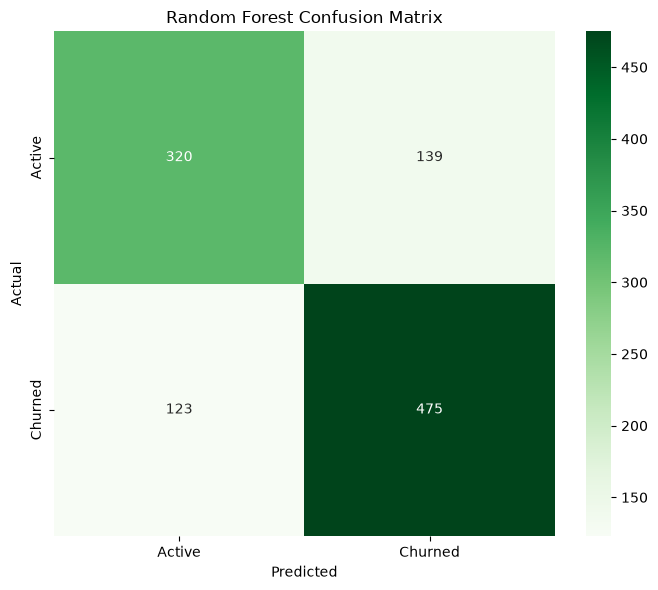

In [41]:
# Save Random Forest confusion matrix  

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Active", "Churned"],
    yticklabels=["Active", "Churned"]
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/random_forest_churn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
# Compare the two models  

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall
    ],
    "F1": [
        logistic_f1,
        rf_f1
    ],
    "ROC_AUC": [
        logistic_auc,
        rf_auc
    ]
})

model_comparison


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.733207,0.792593,0.715719,0.752197,0.800085
1,Random Forest,0.752129,0.773616,0.794314,0.783828,0.812640


## Select the best model

For churn prediction, ROC-AUC is useful for overall ranking, but recall can be especially important because missing a genuinely churned customer may be costly.

We'll select using ROC-AUC for this initial project implementation.

In [43]:
if rf_auc >= logistic_auc:
    best_model = random_forest_model
    best_model_name = "Random Forest"
    best_probability = rf_proba
else:
    best_model = logistic_model
    best_model_name = "Logistic Regression"
    best_probability = logistic_proba

print(
    "Selected model:",
    best_model_name
)

Selected model: Random Forest


## ROC curve

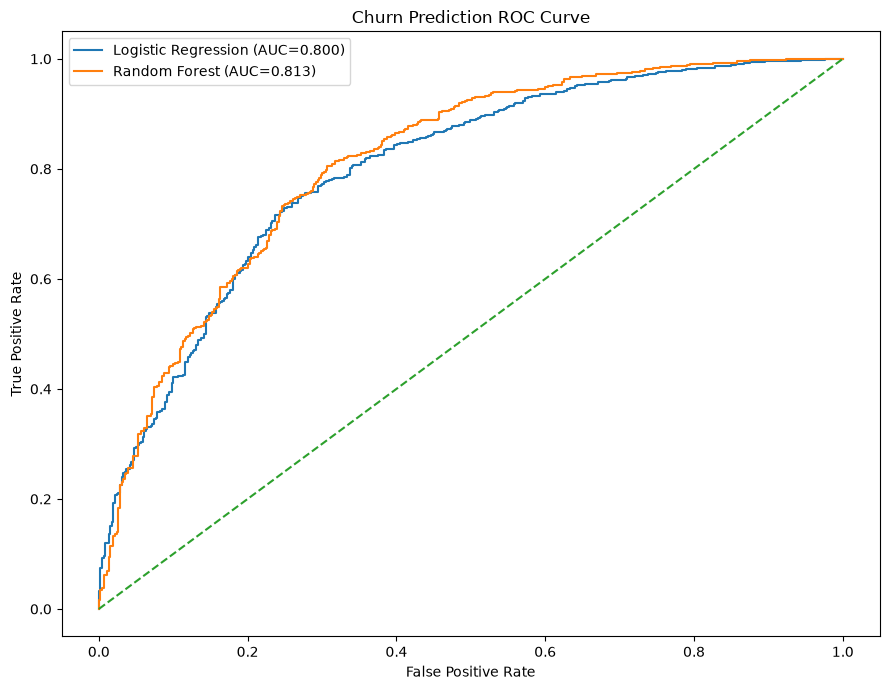

In [44]:
fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test,
    logistic_proba
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    rf_proba
)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC={logistic_auc:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC={rf_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("Churn Prediction ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()
plt.show()

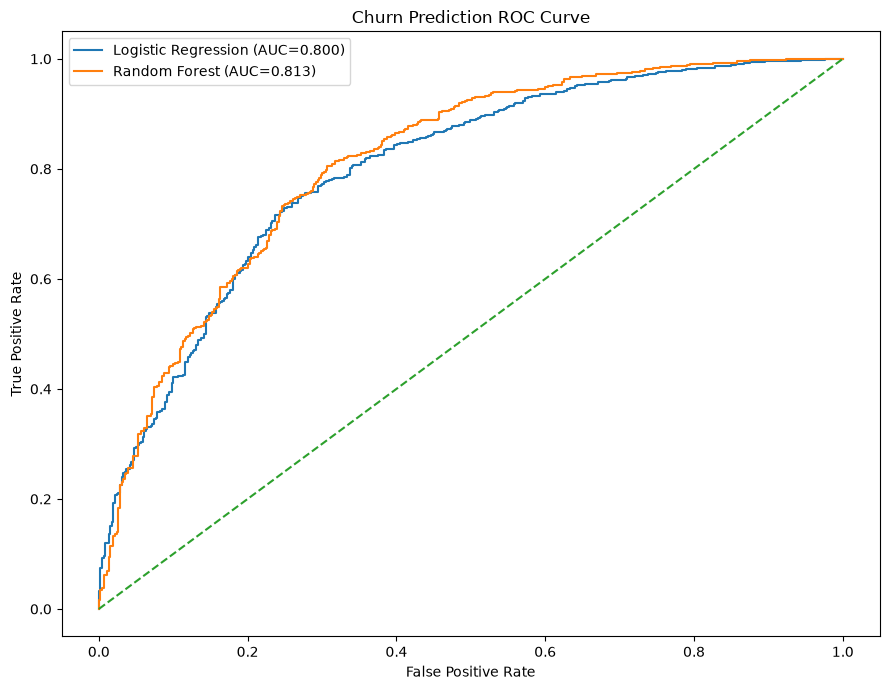

In [45]:
# Save ROC curve  

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC={logistic_auc:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC={rf_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("Churn Prediction ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/churn_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Analyze Random Forest feature importance

If Random Forest is the selected model, feature importance is useful for explaining the model.

In [46]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
)

feature_importance

,Feature,Importance
0,Recency,0.290643
2,Monetary,0.123272
1,Frequency,0.115269
3,TotalQuantity,0.113886
4,UniqueProducts,0.086713
8,OrdersPerMonth,0.086236
6,AverageOrderValue,0.065267
5,CustomerLifetimeDays,0.059743
7,AverageQuantityPerOrder,0.058970


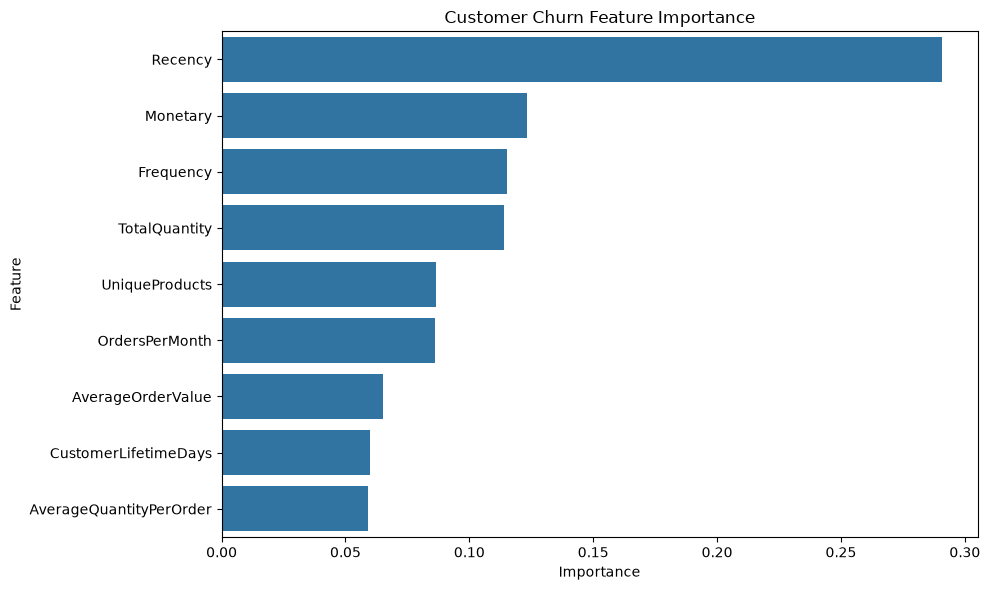

In [47]:
##  Visualize feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Customer Churn Feature Importance"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


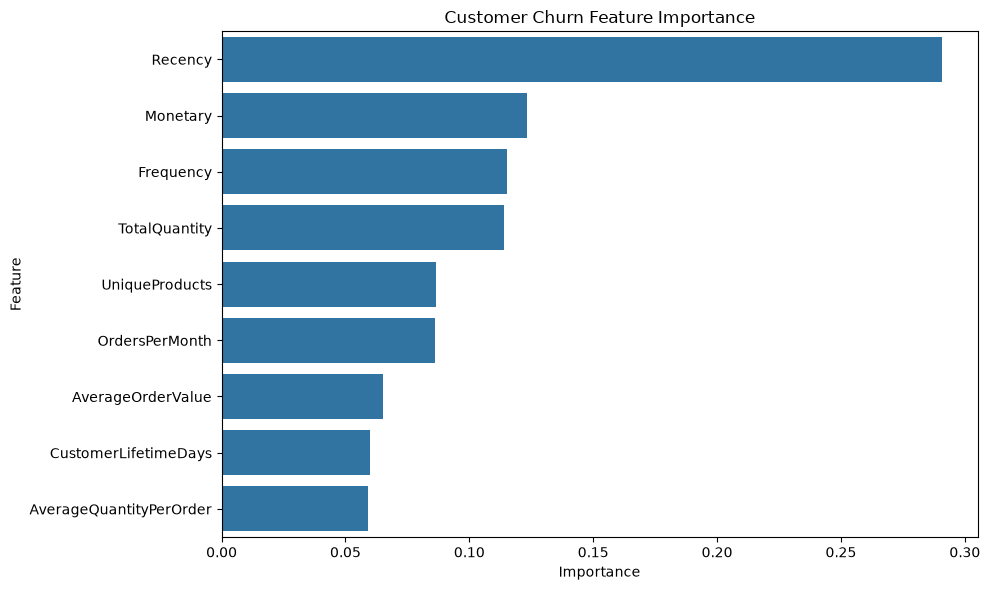

In [48]:
# Save feature importance chart  

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Customer Churn Feature Importance"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/churn_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [49]:
# Generate churn probabilities for all customers

# Now we use the selected model to calculate a churn probability for every customer.   


all_churn_probability = (
    best_model.predict_proba(X)[:, 1]
)

customer_ml["ChurnProbability"] = (
    all_churn_probability
)

customer_ml["PredictedChurn"] = (
    customer_ml["ChurnProbability"] >= 0.50
).astype(int)

customer_ml.head()


,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,FirstPurchase,LastPurchase,CustomerLifetimeDays,AverageOrderValue,AverageQuantityPerOrder,OrdersPerMonth,Churn,ChurnProbability,PredictedChurn
0,12346.0,235,12,77556.46,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,400,6463.038333,6190.416667,0.900000,1,0.556982,1
1,12347.0,39,6,3402.39,2099,107,2010-10-31 14:20:00,2011-08-02 08:48:00,274,567.065000,349.833333,0.656934,0,0.145363,0
2,12348.0,158,4,1709.40,2497,25,2010-09-27 14:59:00,2011-04-05 10:47:00,189,427.350000,624.250000,0.634921,0,0.466862,0
3,12349.0,317,3,2671.14,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00,181,890.380000,331.000000,0.497238,0,0.395698,0
4,12350.0,219,1,334.40,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,0,334.400000,197.000000,0.000000,1,0.841486,1


In [50]:
# Create risk categories

# This will be useful in the dashboard.

# We'll use:

# < 30%       Low Risk
# 30–60%      Medium Risk
# 60–80%      High Risk
# >= 80%      Critical Risk 

In [51]:
def churn_risk(probability):
    
    if probability < 0.30:
        return "Low Risk"
    
    elif probability < 0.60:
        return "Medium Risk"
    
    elif probability < 0.80:
        return "High Risk"
    
    else:
        return "Critical Risk"

In [52]:
customer_ml["ChurnRisk"] = (
    customer_ml["ChurnProbability"]
    .apply(churn_risk)
)

customer_ml.head()

,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,FirstPurchase,LastPurchase,CustomerLifetimeDays,AverageOrderValue,AverageQuantityPerOrder,OrdersPerMonth,Churn,ChurnProbability,PredictedChurn,ChurnRisk
0,12346.0,235,12,77556.46,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,400,6463.038333,6190.416667,0.900000,1,0.556982,1,Medium Risk
1,12347.0,39,6,3402.39,2099,107,2010-10-31 14:20:00,2011-08-02 08:48:00,274,567.065000,349.833333,0.656934,0,0.145363,0,Low Risk
2,12348.0,158,4,1709.40,2497,25,2010-09-27 14:59:00,2011-04-05 10:47:00,189,427.350000,624.250000,0.634921,0,0.466862,0,Medium Risk
3,12349.0,317,3,2671.14,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00,181,890.380000,331.000000,0.497238,0,0.395698,0,Medium Risk
4,12350.0,219,1,334.40,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,0,334.400000,197.000000,0.000000,1,0.841486,1,Critical Risk


In [53]:
# Count customers by risk  

risk_summary = (
    customer_ml["ChurnRisk"]
    .value_counts()
    .reset_index()
)

risk_summary.columns = [
    "ChurnRisk",
    "Customers"
]

risk_summary

,ChurnRisk,Customers
0,Medium Risk,1622
1,High Risk,1364
2,Low Risk,1298
3,Critical Risk,997


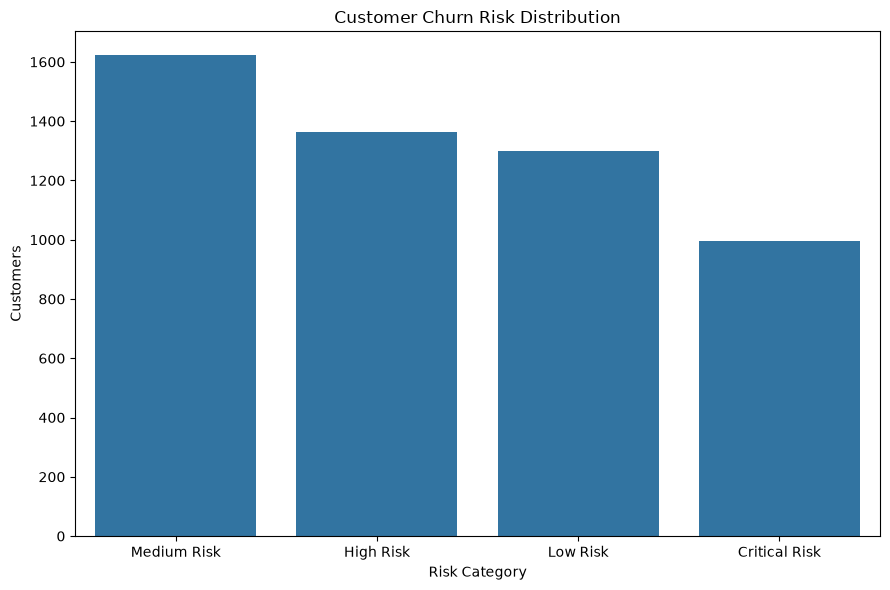

In [54]:
# Visualize churn risk 

plt.figure(figsize=(9, 6))

sns.barplot(
    data=risk_summary,
    x="ChurnRisk",
    y="Customers"
)

plt.title(
    "Customer Churn Risk Distribution"
)

plt.xlabel("Risk Category")
plt.ylabel("Customers")

plt.tight_layout()
plt.show()


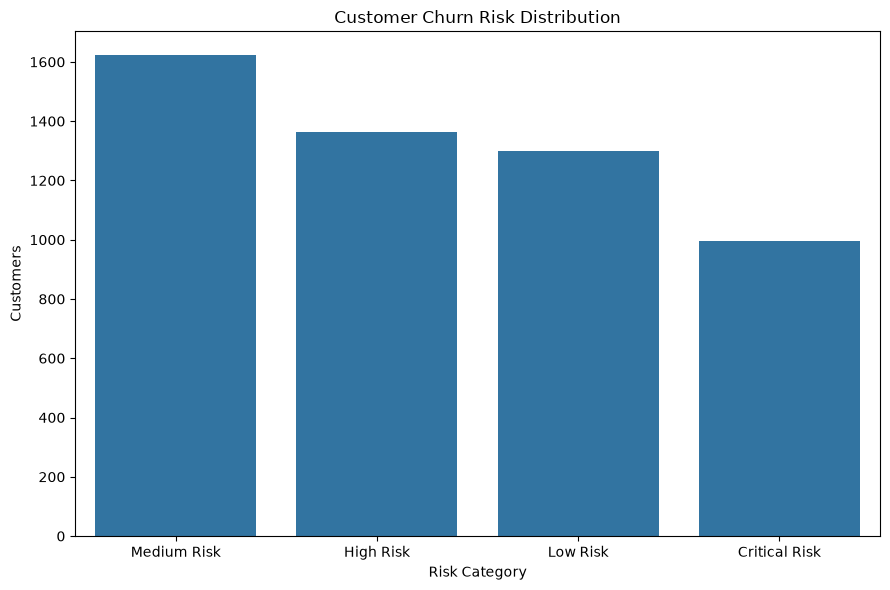

In [55]:
## save churn risk chart

plt.figure(figsize=(9, 6))

sns.barplot(
    data=risk_summary,
    x="ChurnRisk",
    y="Customers"
)

plt.title(
    "Customer Churn Risk Distribution"
)

plt.xlabel("Risk Category")
plt.ylabel("Customers")

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/churn_risk_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:
## Create the final shurnm dataset
## we wnat a clean file containing custoomer-level churn predictions results

churn_output = customer_ml[
    [
        "Customer ID",
        "Recency",
        "Frequency",
        "Monetary",
        "TotalQuantity",
        "UniqueProducts",
        "CustomerLifetimeDays",
        "AverageOrderValue",
        "AverageQuantityPerOrder",
        "OrdersPerMonth",
        "Churn",
        "ChurnProbability",
        "PredictedChurn",
        "ChurnRisk"
    ]
].copy()

churn_output.head()

,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,CustomerLifetimeDays,AverageOrderValue,AverageQuantityPerOrder,OrdersPerMonth,Churn,ChurnProbability,PredictedChurn,ChurnRisk
0,12346.0,235,12,77556.46,74285,27,400,6463.038333,6190.416667,0.900000,1,0.556982,1,Medium Risk
1,12347.0,39,6,3402.39,2099,107,274,567.065000,349.833333,0.656934,0,0.145363,0,Low Risk
2,12348.0,158,4,1709.40,2497,25,189,427.350000,624.250000,0.634921,0,0.466862,0,Medium Risk
3,12349.0,317,3,2671.14,993,90,181,890.380000,331.000000,0.497238,0,0.395698,0,Medium Risk
4,12350.0,219,1,334.40,197,17,0,334.400000,197.000000,0.000000,1,0.841486,1,Critical Risk


In [57]:
## Sort Customer by churn probability 

high_risk_customers = (
    churn_output
    .sort_values(
        "ChurnProbability",
        ascending=False
    )
)

high_risk_customers.head(20)

,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,CustomerLifetimeDays,AverageOrderValue,AverageQuantityPerOrder,OrdersPerMonth,Churn,ChurnProbability,PredictedChurn,ChurnRisk
4015,16867.0,599,1,76.74,58,6,0,76.740,58.0,0.00000,1,0.978847,1,Critical Risk
577,13007.0,489,1,175.25,59,11,0,175.250,59.0,0.00000,1,0.978420,1,Critical Risk
4614,17543.0,459,1,120.05,62,13,0,120.050,62.0,0.00000,1,0.974963,1,Critical Risk
4964,17933.0,541,1,114.69,63,12,0,114.690,63.0,0.00000,1,0.974217,1,Critical Risk
1272,13794.0,456,1,126.03,63,9,0,126.030,63.0,0.00000,1,0.973334,1,Critical Risk
54,12404.0,591,1,63.24,1,1,0,63.240,1.0,0.00000,1,0.973329,1,Critical Risk
2721,15409.0,630,1,131.25,59,9,0,131.250,59.0,0.00000,1,0.973087,1,Critical Risk
1986,14588.0,487,1,135.39,62,16,0,135.390,62.0,0.00000,1,0.970587,1,Critical Risk
3822,16651.0,496,1,136.20,60,6,0,136.200,60.0,0.00000,1,0.970182,1,Critical Risk
543,12969.0,512,1,122.45,55,5,0,122.450,55.0,0.00000,1,0.969704,1,Critical Risk


In [58]:
## Save churn predictions 

processed_dir = "../data/processed"

os.makedirs(
    processed_dir,
    exist_ok=True
)

churn_output.to_csv(
    f"{processed_dir}/customer_churn_predictions.csv",
    index=False
)

print(
    "Saved customer_churn_predictions.csv"
)

Saved customer_churn_predictions.csv


In [59]:
## Save model comparison results

model_comparison.to_csv(
    f"{processed_dir}/churn_model_comparison.csv",
    index=False
)

print(
    "Saved churn_model_comparison.csv"
)

Saved churn_model_comparison.csv


In [60]:
## Save features importance 

feature_importance.to_csv(
    f"{processed_dir}/churn_feature_importance.csv",
    index=False
)

print(
    "Saved churn_feature_importance.csv"
)

Saved churn_feature_importance.csv


In [61]:
## Save the best model for future use
# we need the feature list as well because the API later must and features in the same order as the model was trained on.

model_dir = "../models"

os.makedirs(
    model_dir,
    exist_ok=True
)

joblib.dump(
    best_model,
    f"{model_dir}/churn_model.pkl"
)

joblib.dump(
    feature_columns,
    f"{model_dir}/churn_feature_columns.pkl"
)

print(
    "Best churn model:",
    best_model_name
)

print(
    "Model saved to:",
    f"{model_dir}/churn_model.pkl"
)


Best churn model: Random Forest
Model saved to: ../models/churn_model.pkl


In [63]:
## Save churn metadata

churn_metadata = {
    "target_definition": (
        "Customer is churned if they make no purchase "
        "during the final 90-day holdout period."
    ),
    "churn_window_days": churn_window_days,
    "model": best_model_name,
    "features": feature_columns,
    "logistic_regression": {
        "accuracy": float(logistic_accuracy),
        "precision": float(logistic_precision),
        "recall": float(logistic_recall),
        "f1": float(logistic_f1),
        "roc_auc": float(logistic_auc)
    },
    "random_forest": {
        "accuracy": float(rf_accuracy),
        "precision": float(rf_precision),
        "recall": float(rf_recall),
        "f1": float(rf_f1),
        "roc_auc": float(rf_auc)
    }
}

os.makedirs(
    "../reports/outputs",
    exist_ok=True
)

with open(
    "../reports/outputs/churn_metadata.json",
    "w"
) as f:
    json.dump(
        churn_metadata,
        f,
        indent=4
    )

print(
    "Saved churn_metadata.json"
)



Saved churn_metadata.json


In [66]:
## test the Saved model and feature columns

# This is important because later FastApi will use this model and feature columns to make predictions on new data. We need to ensure that the saved model and feature columns work correctly. 

loaded_model = joblib.load(
    "../models/churn_model.pkl"
)

loaded_features = joblib.load(
    "../models/churn_feature_columns.pkl"
)

print(
    "Loaded model:",
    type(loaded_model)
)

print(
    "Loaded features:",
    loaded_features
)


Loaded model: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Loaded features: ['Recency', 'Frequency', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'CustomerLifetimeDays', 'AverageOrderValue', 'AverageQuantityPerOrder', 'OrdersPerMonth']


In [67]:
## Test prediction  

sample_customer = X.iloc[[0]]

sample_probability = (
    loaded_model
    .predict_proba(sample_customer)[0, 1]
)

sample_prediction = (
    loaded_model
    .predict(sample_customer)[0]
)

print(
    "Churn probability:",
    round(sample_probability, 4)
)

print(
    "Predicted churn:",
    sample_prediction
)


Churn probability: 0.557
Predicted churn: 1


In [68]:
## final validation of the saved model and feature columns

print("=" * 70)
print("RETAILPULSE CUSTOMER CHURN PREDICTION COMPLETE")
print("=" * 70)

print(
    f"Customers modeled: "
    f"{len(customer_ml):,}"
)

print(
    f"Churned customers: "
    f"{customer_ml['Churn'].sum():,}"
)

print(
    f"Churn rate: "
    f"{customer_ml['Churn'].mean() * 100:.2f}%"
)

print(
    f"Selected model: "
    f"{best_model_name}"
)

print(
    f"Model ROC-AUC: "
    f"{max(logistic_auc, rf_auc):.4f}"
)

print(
    f"High/Critical risk customers: "
    f"{customer_ml['ChurnRisk'].isin(['High Risk', 'Critical Risk']).sum():,}"
)

print("=" * 70)

RETAILPULSE CUSTOMER CHURN PREDICTION COMPLETE
Customers modeled: 5,281
Churned customers: 2,989
Churn rate: 56.60%
Selected model: Random Forest
Model ROC-AUC: 0.8126
High/Critical risk customers: 2,361
